# 06 — Model Optimization and Ensemble Comparison

We compare CatBoost, XGBoost, LightGBM, Random Forest, Extra Trees, a PyTorch multilayer perceptron, and fixed probability/rank blends. All results are **out-of-fold predictions** from the labeled 2014–15 accounts; the hidden Kaggle labels are never used.

### Commands to run in the repository root

**1. Initial six-model benchmark (five folds, seed 42)**

```bash
python -m src.model_search --mode benchmark
```

**2. Tune boosting models (15 trials each; can take significantly longer)**

```bash
python -m src.model_search --mode tune --models catboost xgboost lightgbm --trials 15
```

**3. Multi-seed comparison including tuned variants and ensembles**

```bash
python -m src.model_search --mode compare --seeds 42 123 2026
```

Default dataset: original 39 features. Pass `--dataset distance` to evaluate the previously generated 46-feature distance variant in a **separate** report. The script does **not** create or overwrite a Kaggle submission.

**Important:** Tuning and comparing on the same labeled dataset introduces model-selection optimism, even though each individual CV fit excludes its validation fold. An untouched private Kaggle score is the final external check. Avoid selecting models by repeatedly submitting to the public leaderboard.

## 1. Load model-comparison results
Set `DATASET` to `distance` if you specifically ran the model-search commands with `--dataset distance`. The notebook uses `compare` if present, or the preliminary `benchmark` otherwise.

In [10]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve

DATASET = 'distance'  # Change to 'distance' for the 46-feature variant.
ROOT = Path.cwd()
if not (ROOT / 'src' / 'model_search.py').exists():
    ROOT = ROOT.parent
MODEL_DIR = ROOT / 'data' / 'processed' / 'model_search'
MODE = 'compare' if (MODEL_DIR / 'compare' / DATASET / 'summary.csv').exists() else 'benchmark'
RESULTS = MODEL_DIR / MODE / DATASET
assert (RESULTS / 'summary.csv').exists(), 'Run python -m src.model_search --mode benchmark first.'

summary = pd.read_csv(RESULTS / 'summary.csv')
runs = pd.read_csv(RESULTS / 'runs.csv')
folds = pd.read_csv(RESULTS / 'folds.csv')
oof = pd.read_csv(RESULTS / 'oof_predictions.csv', dtype={'account.id': 'string'})
test_preds = pd.read_csv(RESULTS / 'test_predictions.csv', dtype={'ID': 'string'})
with (RESULTS / 'config.json').open(encoding='utf-8') as handle:
    config = json.load(handle)

print('Dataset:', DATASET, '| Mode:', MODE)
print('Seeds:', config['seeds'], '| Folds:', config['folds'])
print('Models:', config['models'])
print('Accounts:', len(oof), '| Hidden test accounts:', len(test_preds))
print('Evaluated candidates and blends:', len(summary))

Dataset: distance | Mode: compare
Seeds: [42, 123, 2026] | Folds: 5
Models: ['catboost']
Accounts: 6941 | Hidden test accounts: 2975
Evaluated candidates and blends: 1


## 2. Model leaderboard (internal CV only)
Rank models by the mean out-of-fold AUROC across seeds. Average precision matters for the rare positive class, but the Kaggle scoring metric is AUROC. A standard deviation of 0.0 with only one seed **does not** imply robustness.

,candidate,family,kind,n_seeds,mean_oof_auc,std_oof_auc,mean_oof_average_precision,delta_vs_original_catboost
0,catboost_default,catboost,single_model,3,0.96941,0.00292,0.833,0.0


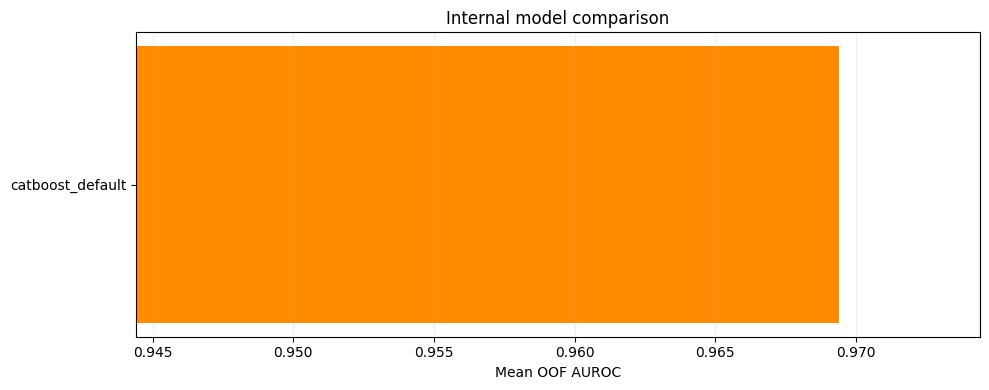

In [11]:
display(summary[['candidate', 'family', 'kind', 'n_seeds', 'mean_oof_auc',
                 'std_oof_auc', 'mean_oof_average_precision',
                 'delta_vs_original_catboost']].round(5))

ordered = summary.sort_values('mean_oof_auc').tail(15)
colors = ['darkorange' if name == 'catboost_default' else
          '#267c9d' if kind == 'single_model' else '#45955d'
          for name, kind in zip(ordered['candidate'], ordered['kind'])]
fig, ax = plt.subplots(figsize=(10, max(4, 0.37 * len(ordered))))
ax.barh(ordered['candidate'], ordered['mean_oof_auc'], color=colors)
ax.set(xlabel='Mean OOF AUROC', title='Internal model comparison')
ax.set_xlim(max(0.5, ordered['mean_oof_auc'].min() - 0.025),
            min(1, ordered['mean_oof_auc'].max() + 0.005))
ax.grid(axis='x', alpha=0.2)
plt.tight_layout()
plt.show()

## 3. Hyperparameter tuning results
These files appear after the `tune` command. The best *tuning* AUROC is the score used to choose parameters and should not be reported as an unbiased generalization estimate.

In [12]:
tuning_dir = MODEL_DIR / 'tuning' / DATASET
tuning_rows = []
for family in ['catboost', 'xgboost', 'lightgbm']:
    path = tuning_dir / f'{family}_best.json'
    if path.exists():
        item = json.loads(path.read_text(encoding='utf-8'))
        tuning_rows.append({
            'family': family, 'tuning_oof_auc': item['best_tuning_oof_auc'],
            'trials': item['trials'], 'best_parameters': item['parameters']
        })
if tuning_rows:
    display(pd.DataFrame(tuning_rows))
else:
    print('No tuning files yet. Run python -m src.model_search --mode tune ...')

No tuning files yet. Run python -m src.model_search --mode tune ...


## 4. Consistency across random seeds
Paired comparisons are most useful when the candidates share exactly the same account-level validation folds. Inspect whether an apparent improvement recurs across multiple seeds.

In [13]:
by_seed = runs.pivot(index='candidate', columns='seed', values='oof_auc')
display(by_seed.loc[summary['candidate']].round(5))

if len(config['seeds']) > 1 and 'catboost_default' in by_seed.index:
    delta = by_seed.subtract(by_seed.loc['catboost_default'], axis='columns')
    display(delta.loc[summary['candidate']].round(5).rename_axis('Delta vs CatBoost', axis=0))
else:
    print('Only one seed was run, or the CatBoost reference was omitted.')

seed,42,123,2026
candidate,,,
catboost_default,0.97255,0.96679,0.96889


seed,42,123,2026
Delta vs CatBoost,,,
catboost_default,0.0,0.0,0.0


## 5. ROC and precision-recall curves
Draw only the best few candidates on the **first seed's OOF predictions** for readability. These are validation predictions, not training-fit predictions.

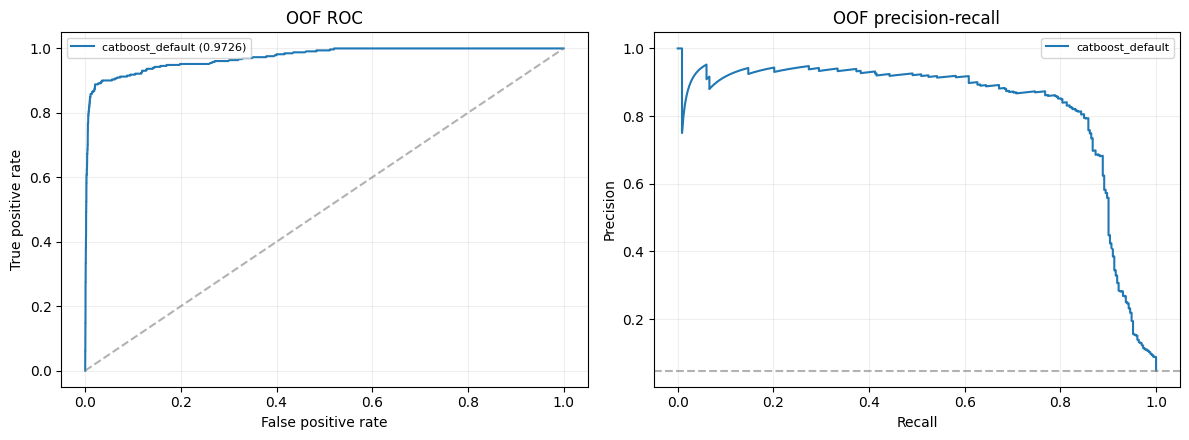

In [14]:
seed = config['seeds'][0]
y = oof['label'].to_numpy()
leaders = summary.head(min(5, len(summary)))['candidate'].tolist()
if 'catboost_default' in summary['candidate'].to_numpy() and 'catboost_default' not in leaders:
    leaders[-1] = 'catboost_default'
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for candidate in leaders:
    prob = oof[f'pred_{candidate}_seed_{seed}'].to_numpy()
    fpr, tpr, _ = roc_curve(y, prob)
    precision, recall, _ = precision_recall_curve(y, prob)
    axes[0].plot(fpr, tpr, label=f'{candidate} ({roc_auc_score(y, prob):.4f})')
    axes[1].plot(recall, precision, label=candidate)
axes[0].plot([0, 1], [0, 1], '--', color='gray', alpha=0.6)
axes[1].axhline(y.mean(), linestyle='--', color='gray', alpha=0.6)
axes[0].set(xlabel='False positive rate', ylabel='True positive rate', title='OOF ROC')
axes[1].set(xlabel='Recall', ylabel='Precision', title='OOF precision-recall')
for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 6. Prediction diversity among the top single models
An ensemble only helps when its components make somewhat different ranking errors. This correlation matrix compares their **OOF scores on the same accounts**. Very highly correlated models may add limited value when averaged.

In [15]:
singles = summary[summary['kind'] == 'single_model'].head(8)['candidate'].tolist()
probabilities = pd.DataFrame({
    candidate: oof[f'pred_{candidate}_seed_{seed}'] for candidate in singles
})
correlation = probabilities.corr(method='spearman')
display(correlation.round(3))
if len(singles) > 1:
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(correlation, vmin=0.65, vmax=1, cmap='Blues')
    ax.set_xticks(range(len(singles)), singles, rotation=45, ha='right')
    ax.set_yticks(range(len(singles)), singles)
    plt.colorbar(im, ax=ax, label='Spearman correlation')
    ax.set_title('OOF prediction rank correlation')
    plt.tight_layout()
    plt.show()

,catboost_default
catboost_default,1.0


## 7. Ensemble performance
Probability means and rank means use fixed equal weights selected **before viewing validation results**. This prevents training blend weights directly on the same OOF labels. If there are no blends yet, execute the `compare` mode.

In [16]:
ensemble_scores = summary[summary['family'] == 'blend']
if len(ensemble_scores):
    display(ensemble_scores[['candidate', 'kind', 'mean_oof_auc',
                             'mean_oof_average_precision',
                             'delta_vs_original_catboost']].round(5))
    print('Blend membership:', config.get('predeclared_blends', {}))
else:
    print('Ensemble results are created in --mode compare, not benchmark.')

Ensemble results are created in --mode compare, not benchmark.


## 8. Paired bootstrap for the leading candidate
This resamples accounts for a **single seed**. It provides a descriptive interval, not an untouched external validation, especially because the winner was selected using CV on these labels.

In [17]:
best = summary.iloc[0]['candidate']
if best == 'catboost_default' or 'catboost_default' not in summary['candidate'].tolist():
    print('The original CatBoost is best, or no common CatBoost reference exists.')
else:
    first_seed = config['seeds'][0]
    p_base = oof[f'pred_catboost_default_seed_{first_seed}'].to_numpy()
    p_new = oof[f'pred_{best}_seed_{first_seed}'].to_numpy()
    rng = np.random.default_rng(2026)
    differences = []
    for _ in range(350):
        idx = rng.integers(0, len(y), len(y))
        if np.unique(y[idx]).size < 2:
            continue
        differences.append(roc_auc_score(y[idx], p_new[idx]) -
                           roc_auc_score(y[idx], p_base[idx]))
    print('Winning candidate:', best)
    print('Paired AUROC delta interval (seed', first_seed, '):',
          np.round(np.quantile(differences, [0.025, 0.5, 0.975]), 5))

The original CatBoost is best, or no common CatBoost reference exists.


## 9. Output verification
The workflow saves **account-aligned test predictions**, but never uploads to Kaggle or changes `submission.csv`. Candidate selection and exact Kaggle CSV export can be performed once we review validation results together.

In [18]:
assert len(oof) == config['training_accounts']
assert len(test_preds) == config['test_accounts']
assert oof['account.id'].is_unique and test_preds['ID'].is_unique
assert (oof['label'].isin([0,1])).all()
pred_cols = [col for col in oof if col.startswith('pred_')]
for col in pred_cols:
    assert np.isfinite(oof[col]).all() and oof[col].between(0, 1).all()
print('Aligned OOF predictions:', len(pred_cols), 'columns')
print('Aligned test accounts:', len(test_preds))

Aligned OOF predictions: 3 columns
Aligned test accounts: 2975


## 10. Conclusions and next decision

After running the model comparison, write down:

1. Best **single model** and its mean AUROC, average precision, and seed-to-seed variability.
2. Whether tuned CatBoost consistently beats the original configuration.
3. Whether XGBoost or LightGBM offers a meaningful gain or complementary predictions.
4. How the neural network compares and whether it contributes to blends.
5. Whether fixed probability/rank blending improves on the strongest individual model.

**Before submitting:** Validate the best configuration on the selected feature table, inspect the top few contenders, and generate an ID-aligned probability CSV separately. Do not use repeated public leaderboard submissions as an optimization objective.